# Pillow sandbox - rotating contour maps

In [1]:
import sys
sys.path.insert(0, "../")

In [2]:
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches

from matplotlib import ticker
from matplotlib.figure import Figure

from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [3]:
z_slice_mosh = 25
bins_mosh = 85
dose_grid_half_mosh = 2.5
lattice_mosh = dose_grid_half_mosh*2/bins_mosh
source_transZ_mosh = -0.5
source_plane_mosh = cm_to_voxel(np.array(source_transZ_mosh), bins_mosh, dose_grid_half_mosh*2/bins_mosh)

In [4]:
applicator_rad = 0.3
source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-2.5, 2.5)
rngY = (-2.5, 2.5)

In [5]:
dose = 20 # Gy
dose_point = (0.0, 0.5) # cm - in center of roi

In [6]:
mosh = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_10_5rod_6rod/5rods_12oclock_open_1e7_85bins_2.5cmHL.csv"

norm_energy, voxel = extract_norm_energy(mosh, source_plane_mosh, 2, dose_point, bins_mosh, lattice_mosh)

Xm, Ym, energy, __ = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane_mosh, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy, dose=dose, zero_source=True, std_dev=False)

## Using matplotlib

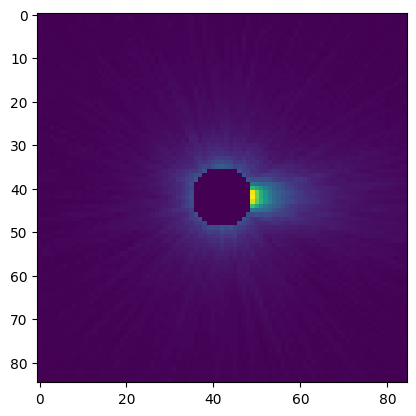

In [7]:
image = plt.imshow(energy)

In [8]:
r = plt.gcf().canvas.get_renderer()
x = image.make_image(r)
#print(x[0])
xp = np.asarray(x[0])
print(np.shape(xp))

(370, 370, 4)


<Figure size 640x480 with 0 Axes>

## Using pillow

In [9]:
from PIL import Image

In [10]:
# Testing rotation
Im = Image.fromarray(energy)
Im = Im.rotate(75)
new_energy = np.array(Im)

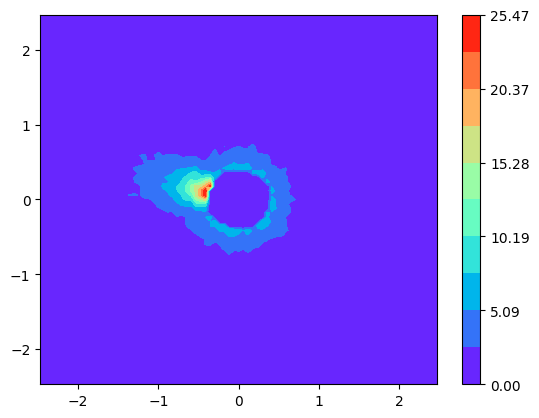

In [11]:
fig0, ax0 = plt.subplots()
Xv0, Yv0 = np.meshgrid(Xm, Ym, indexing='ij')
contour0 = ax0.contourf(Xv0, Yv0, new_energy, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")

cbar0 = fig0.colorbar(contour0)

# Rotation works, but still lose data
# This module looks much easier to use than my home-grown functions though!

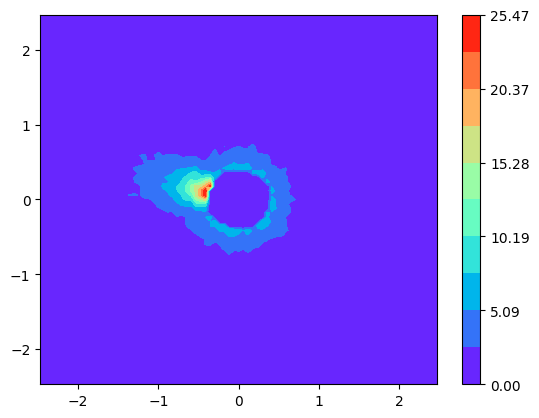

In [13]:
# Testing rotation function in plotting_functions.py
theta = 75
rotated_energy = rotate_applicator(energy, theta)

fig1, ax1 = plt.subplots()
Xv1, Yv1 = np.meshgrid(Xm, Ym, indexing='ij')
contour1 = ax1.contourf(Xv1, Yv1, new_energy, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")

cbar1 = fig1.colorbar(contour1) # distributions match